# **Lab session 1**
## **Exercise 1 : Implementation of the XOR (eXclusive OR) function**
The XOR function is a logical funtion used in electronic circuits (processors, memories, ...). The interest of using it here is that the XOR function is impossible to approximate with linear classifiers.

In this exercise we will benefit from the inherent nonlinearity of neural networks to implement an estimator of the XOR function. 

We will use a perceptron with one hidden and one output layer.

**(This assignment contains examples of results you should be able to reproduce with your code.)**

## Implement the XOR function. 

XOR is a two-input function. The inputs admit binary values, that is a 0 or a 1. The output is also binary.

The function outputs 1 when the inputs are different, and 0 otherwise. In other words, the XOR function implements "is not equal to".

Use the python inequality operator != to generate the table of XOR. The inputs are observations X, and the output is our dependent variable Y. Create a two-column array X and a vector Y.

In [ ]:
import numpy as np

def XOR_array(X):
    return (X[:, 0] != X[:, 1]).astype(int) 

X = np.array([[0,0],[0,1],[1,0],[1,1]])
Y = XOR_array(X)

print ("X=",X)
print ("Y=",Y)

X= [[0 0]
 [0 1]
 [1 0]
 [1 1]]
Y= [0 1 1 0]


## Represent this function graphically

It can be done easily cause we are in a 2-D space. The inputs X are on the two axis, respectively, and the output value is in colour. Use the **matplotlib.pyplot** function **scatter** to plot the examples.

(-0.5, 1.5, -0.5, 1.5)

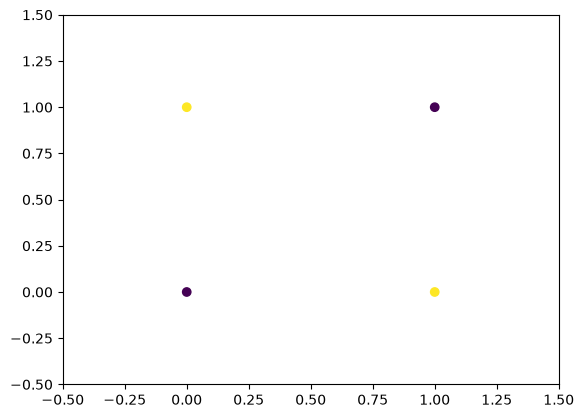

In [ ]:
from matplotlib import pyplot as plt

plt.scatter (X[:,0],X[:,1],c=Y) #c is used to color the points based on their labels
plt.axis([-.5,1.5,-.5,1.5])

**Why can not one use a linear classifier to classify these data?**

The perceptron is **not a maximal-margin classifier**. We would encounter convergence issues with sparsely distributed examples. Replicate the data (use **numpy.tile()** function) and add some noise to ease the convergence ( use **numpy.random.randn()** function).

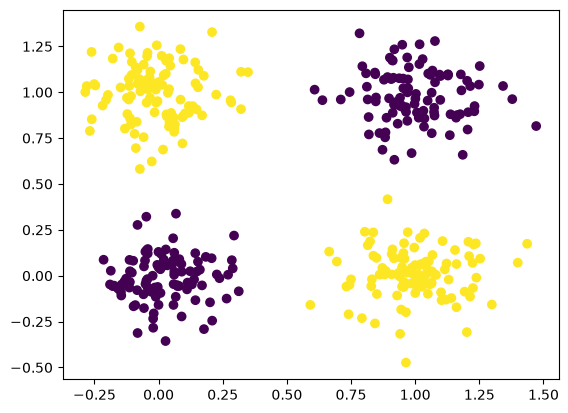

In [8]:


n_rep = 100 # generate a random number of repetitions between 2 and 10

X_rep= np.tile(X,(n_rep,5)) # create a copy of X with random number of repetitions
Y_rep= np.tile(Y,n_rep) # create a copy of Y with random number of repetitions
noise= 0.15* np.random.randn(*X_rep.shape)
# *X_rep.shape is used to get the shape of X_rep and generate noise of the same shape
#0.15 is the standard deviation of the noise
X_rep_noisy= X_rep + noise
plt.scatter (X_rep_noisy[:,0],X_rep_noisy[:,1],c=Y_rep) 


Convert the target into the matrix 'y' in one-hot format.
This will allow the predictors output one at a time using the soft-max activation. What is the shape of the 'y' matrix. Use the **keras** function **utils.to_categorical()**.

In [9]:

from tensorflow import keras

Y_one=keras.utils.to_categorical(Y_rep, num_classes=2) # convert Y to one-hot encoding

display(Y_one) # display the one-hot encoded Y
print("Y_one shape=",Y_one.shape)


array([[1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.

Y_one shape= (400, 2)


## Prepare the train and test dataset.

1.   split dataset into test and train dataset. The test will be used once the training stops to test the model on data that the model haven't seen during the training.
2.   split further the train dataset into train and validation part. The validation is used to prevent overfitting.

Use the **sklearn.model_selection** function **train_test_split()** to separate a dataset. You can choose the percentage of the split, or leave the defaut value.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X_rep_noisy, Y_one, test_size=0.2, random_state=42) 

## create the model

1.   The model will be the keras sequential model containing one hidden and one output layer.
Instantiate the model using **model=Sequential()**, then add two **Dense()** layers from **keras.layers**. Adding layers can be done using the model's class function **model.add()**.
For the hidden (the first) layer, specify the input shape, and for the output layer the number of classes to output. Use the relu activation in the hidden layer and the softmax for the output layer?
2.   Compile the model. Specify the loss (use **categorical_entropy**). Choose an optimizer and the evaluation metrics (use **accuracy**) to use. Use the class function **compile()** of the sequential model you have created.



In [9]:
from keras.models import Sequential
from keras.layers import Dense

model = Sequential()
model.add(Dense(8, input_dim=2, activation='relu')) # input layer with 2 neurons and hidden layer with 8 neurons
model.add(Dense(2, activation='softmax')) # output layer with 2 neurons for 2 classes
    


model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/Users/reginaseca/miniforge3/envs/psl/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## train the model

You need to specify the size of the batch and the number of epochs to train. You need to provide the training and the validation data.

Use the sequential model's class function **fit()** to train the model.

How many epochs do you need to have the training converge?

In [ ]:
history = model.fit(x_train, y_train, epochs=200, verbose=0, validation_data=(x_val,y_val))

Display the training history. Plot the accuracy and loss for the training and validation datasets.

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


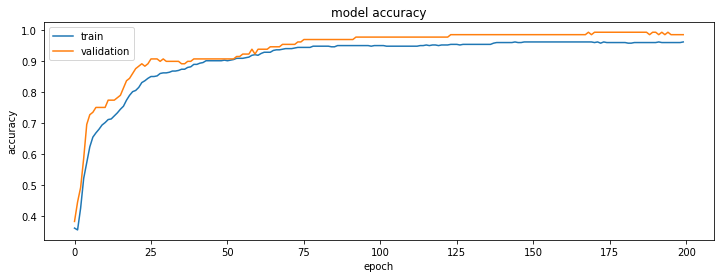

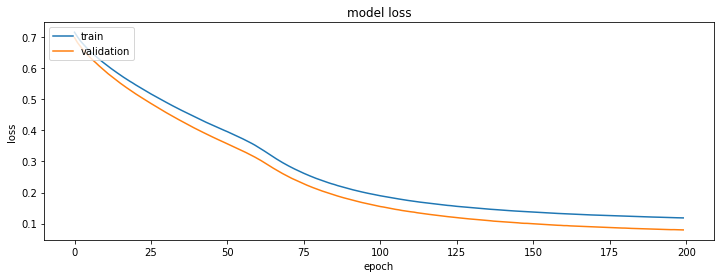

In [ ]:
print(history.history.keys())
import matplotlib.pyplot as plt

# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

... < complete code here >



## Analyze the results.

1.   Print a summary of the model - use the model's class function **summary()**. How many parameters does the model have? Is a big or a small model?
2.   What was the accuracy we obtained at the end of the training? Do you use the training or validation accuracy to answer?
3. If you run the model several times, do you always obtain the same accuracy? 

In [ ]:

... < complete code here >

Model: "sequential_9"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_18 (Dense)             (None, 6)                 18        
_________________________________________________________________
dense_19 (Dense)             (None, 2)                 14        
Total params: 32
Trainable params: 32
Non-trainable params: 0
_________________________________________________________________
None


## print the confusion matrix obtained on the test dataset.

Test the model by examining the confusion matrix on the "test" subset.

Use the **confusion_matrix()** function provided in **sklearn.metrics**.

In [ ]:

from sklearn.metrics import confusion_matrix

... < complete code here >

[[78  3]
 [ 5 74]]


Normalize the confusion matrix to show graphically the prediction probability map.

Hint: The confusion matrix needs to be normalized by the counts of each class. Print the counts of elements in each class in the test dataset. Use the numpy function **unique()** to count the elements in y_test.

[81 79]


Text(0.5, 0, 'predicted label')

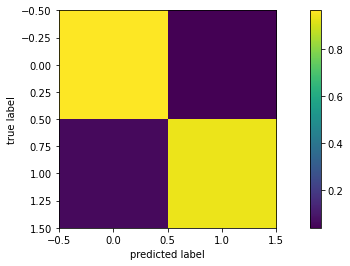

In [ ]:

... < complete code here >

plt.figure('confusion matrix')
ax = plt.imshow(CM); plt.colorbar()
plt.ylabel('true label')
plt.xlabel('predicted label')

Evaluate the model on the test dataset. What is the accuracy on the test dataset? Use the model's class function **evaluate()**.

In [ ]:

... < complete code here >

5/5 [==============================] - 0s 2ms/step - loss: 0.1340 - accuracy: 0.9500
The loss and accuracy on the test dataset : 0.133967, 0.950000


##plot the decision boundary of the classifier

The fitted estimator produces a prediction of the function for all combinations of the inputs. Not only binary values as in the case of the logical XOR function (even though strictly speaking electronic circuits are also designed to be resilient to noise and do accept noisy inputs too).

In order to plot the decision boundary, create a grid of all combinations of the inputs. Use the numpy **meshgrid** function to create a squared grid of coordinates, of say 10x10 points of size.

Use these coordinates as input values for the XOR estimator. Convert the coordinates to an array of observations. Make a prediction on them and save in in Y_hat. Reshape Y_hat to have the shape of the grid. Use the **matplotlib.pyplot** function **contour** to plot the level zero of the function.

Increase the size of the grid, say to 100x100, to obtain a smoother representation.


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:14: UserWarning: No contour levels were found within the data range.
  


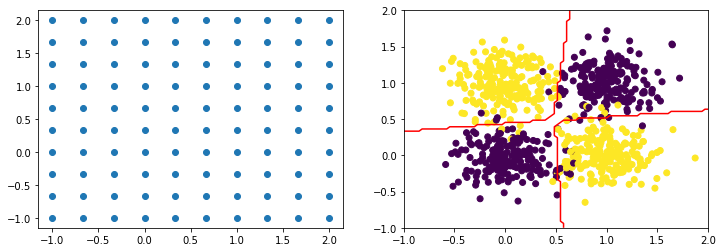

In [ ]:

... < complete code here >



## **Conclusions:**
Conclude your report by answering the following questions:

1. Did your training converge? 
2. Was the training successful? 
3. Report the confusion matrix.
4. What shape has the decision boundary? Is it a linear classifier? 
5. What is the minimum of neurons you need in the hidden layer?


#Produce and upload to moodle a pdf report from this exercise. 

Use the following piece of code to generate your report automatically. 

(Do not forget to answer the above questions.)

In [ ]:
from google.colab import drive
base_working_dir = '/content/drive/My Drive/Colab Notebooks/MBE DL course'
drive.mount('/content/drive')

!sudo apt-get install texlive-xetex texlive-fonts-recommended texlive-generic-recommended

!jupyter nbconvert --to pdf "drive/My Drive/Colab Notebooks/MBE DL course/exercise_1_assignment.ipynb"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Reading package lists... Done
Building dependency tree       
Reading state information... Done
texlive-fonts-recommended is already the newest version (2017.20180305-1).
texlive-generic-recommended is already the newest version (2017.20180305-1).
texlive-xetex is already the newest version (2017.20180305-1).
0 upgraded, 0 newly installed, 0 to remove and 11 not upgraded.
[NbConvertApp] Converting notebook drive/My Drive/Colab Notebooks/MBE DL course/exercise_1_assignment.ipynb to pdf
[NbConvertApp] Support files will be in exercise_1_assignment_files/
[NbConvertApp] Making directory ./exercise_1_assignment_files
[NbConvertApp] Making directory ./exercise_1_assignment_files
[NbConvertApp] Making directory ./exercise_1_assignment_files
[NbConvertApp] Making directory ./exercise_1_assignment_files
[NbConvertApp] Making directory ./exercise_1_assignment_files
[N